# Using SIMPLEOmics to integrate paired spatial transcriptomics and metabolomics data from a 6-OHDA-induced mouse model of Parkinson’s disease

## 1. Load packages

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import SIMPLEOmics

# the location of R (used for the mclust clustering)
import os
os.environ['R_HOME'] = "/home/lvyz/miniconda3/envs/SIMPLEOmics_env/lib/R"
os.environ['R_USER'] = "/home/lvyz/miniconda3/envs/SIMPLEOmics_env/lib/python3.8/site-packages/rpy2"

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "svg.fonttype": "none"
})
import scanpy as sc
import numpy as np
from scipy.sparse import csr_matrix
import torch
used_device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
print(torch.cuda.is_available())

# set seed
seed=2026
SIMPLEOmics.ST_utils.fix_seed(seed)


True


## 2. Load data and preprocess for training

In [ ]:
# load data
n_cluster = 12

adata_ST=sc.read_h5ad("data_SIMPLEOmics/ST_metabolite_mouse_brain/adata_RNA_with_annotations.h5ad")
adata_SM=sc.read_h5ad("data_SIMPLEOmics/ST_metabolite_mouse_brain/adata_META.h5ad")
print(f"adata_ST: {adata_ST}")
print(f"adata_SM: {adata_SM}")
adata_ST.obs['annotation'] = adata_ST.obs['Ground Truth']

adata_ST.var_names_make_unique()
adata_SM.var_names_make_unique()

# RNA
if isinstance(adata_ST.X, np.ndarray):
    adata_ST.X = csr_matrix(adata_ST.X)
sc.pp.filter_genes(adata_ST, min_cells=10)
sc.pp.highly_variable_genes(adata_ST, flavor="seurat_v3", n_top_genes=5000)
sc.pp.normalize_total(adata_ST, target_sum=1e4)
sc.pp.log1p(adata_ST)
sc.pp.scale(adata_ST)
adata_high =  adata_ST[:, adata_ST.var['highly_variable']]
adata_ST.obsm['feat'] = SIMPLEOmics.ST_utils.pca(adata_ST, n_comps=60,random_state=seed)
adata_ST=SIMPLEOmics.Cal_Net(adata_ST)

# Metabolite
sc.pp.filter_genes(adata_SM, min_cells=10)
sc.pp.normalize_total(adata_SM, target_sum=1e4)
sc.pp.log1p(adata_SM)
adata_SM.obsm['feat'] = SIMPLEOmics.ST_utils.pca(adata_SM, n_comps=60,random_state=seed)
adata_SM=SIMPLEOmics.Cal_Net(adata_SM)

adata_ST: AnnData object with n_obs × n_vars = 3058 × 32285
    obs: 'in_tissue', 'array_row', 'array_col', 'RegionLoupe', 'region', 'lesion', 'Ground Truth_anatomical', 'Ground Truth', 'annotation'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
adata_SM: AnnData object with n_obs × n_vars = 3058 × 1538
    obs: 'in_tissue', 'array_row', 'array_col', 'matched_msi_pixels', 'nearest_msi_distance'
    uns: 'spatial', 'spatialmeta_reassignment'
    obsm: 'spatial'
------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 18348
------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 18348


## 3. Train SIMPLEOmics

In [4]:
adata_ST,adata_SM=SIMPLEOmics.train(adata_ST,adata_SM,num_prototype=n_cluster,n_epochs=800,device=used_device,random_seed=seed)

training SIMPLEOmics...


100%|██████████| 800/800 [01:36<00:00,  8.26it/s]


## 4. Clustering

In [5]:
SIMPLEOmics.ST_utils.mclust_R(adata_ST, num_cluster=n_cluster, used_obsm='SIMPLEOmics',random_seed=seed)
adata_ST.obs["mclust"] = adata_ST.obs["mclust"].astype(int).astype("category")

# ARI
adata1 = adata_ST[adata_ST.obs['annotation'].notna(), :].copy()
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(adata1.obs['annotation'], adata1.obs['mclust'])
print(ari)

R[write to console]:     __  ___________    __  _____________
   /  |/  / ____/ /   / / / / ___/_  __/
  / /|_/ / /   / /   / / / /\__ \ / /   
 / /  / / /___/ /___/ /_/ /___/ // /    
/_/  /_/\____/_____/\____//____//_/    version 5.4.7
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%
0.4315136531755346


## 5. Visualization

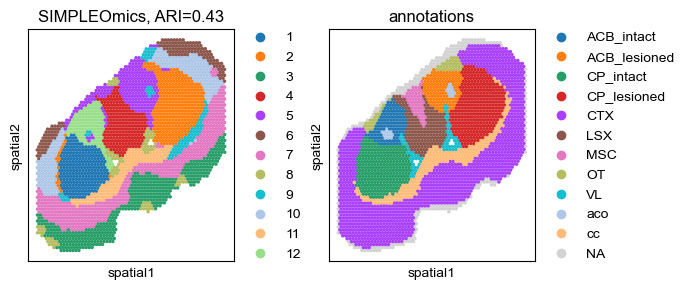

In [6]:
import matplotlib.pyplot as plt
fig, ax_list = plt.subplots(1, 2, figsize=(7, 3))
sc.pl.embedding(adata_ST, basis='spatial', color='mclust', ax=ax_list[0], title='SIMPLEOmics, ARI='+str(round(ari, 2)), s=25, show=False)
sc.pl.embedding(adata_ST, basis='spatial', color='annotation', ax=ax_list[1], title='annotations', s=25, show=False)
plt.tight_layout(w_pad=0.3)
plt.show()